In [14]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import os,csv,re

* 进入文件路径

In [2]:
os.getcwd()
#os.chdir(r'data_analysis\FZU')

'e:\\projects\\collection-ai\\foundation\\hyzzz145\\task-2\\data_analysis\\FZU'

* 抓取通知人个数

In [ ]:
notice_people = pd.Series({})
with open('data_file/content.csv','r',encoding='utf-8') as f:
    for lines in f:
        if '通知人：' in lines:
            people = lines.replace('通知人：','').strip()
            if people in notice_people.keys():
                notice_people[people] += 1
            else:
                notice_people[people] = 1

: 

* 抓取课程调整类通知

In [ ]:
with open('data_file/content.csv','r',encoding='utf-8',newline='') as f:
    with open('data_file/course_adjust.csv','w',encoding='utf-8',newline='') as g:
        writer = csv.writer(g)
        #history 用于查找保存
        history = []
        collection = False
        idx = 0
        print('准备遍历csv')
        for lines in f:
            lines = lines.strip()
            history.append(lines)
            if not collection and len(history)>2:
                history.pop(1)
            if '课程调整' in lines:
                idx += 1
                print(f'查询到第{idx}个‘课程调整’')
                collection = True
            if lines.strip() == '' and collection:
                history.pop(-1)
                writer.writerow([f'-------------第{idx}个课程调整----------'])
                writer.writerows([[i] for i in history])
                writer.writerow([' '])
                print(f'已写入第{idx}个‘课程调整’')
                history.clear()
                collection = False

print('over')
    
       

            
        

准备遍历csv
查询到第1个‘课程调整’
已写入第1个‘课程调整’
查询到第2个‘课程调整’
已写入第2个‘课程调整’
查询到第3个‘课程调整’
已写入第3个‘课程调整’
查询到第4个‘课程调整’
已写入第4个‘课程调整’
查询到第5个‘课程调整’
已写入第5个‘课程调整’
查询到第6个‘课程调整’
已写入第6个‘课程调整’
查询到第7个‘课程调整’
已写入第7个‘课程调整’
查询到第8个‘课程调整’
已写入第8个‘课程调整’
查询到第9个‘课程调整’
已写入第9个‘课程调整’
查询到第10个‘课程调整’
已写入第10个‘课程调整’
查询到第11个‘课程调整’
已写入第11个‘课程调整’
查询到第12个‘课程调整’
已写入第12个‘课程调整’
查询到第13个‘课程调整’
已写入第13个‘课程调整’
查询到第14个‘课程调整’
已写入第14个‘课程调整’
查询到第15个‘课程调整’
已写入第15个‘课程调整’
查询到第16个‘课程调整’
已写入第16个‘课程调整’
查询到第17个‘课程调整’
已写入第17个‘课程调整’
查询到第18个‘课程调整’
已写入第18个‘课程调整’
查询到第19个‘课程调整’
已写入第19个‘课程调整’
查询到第20个‘课程调整’
已写入第20个‘课程调整’
查询到第21个‘课程调整’
已写入第21个‘课程调整’
查询到第22个‘课程调整’
已写入第22个‘课程调整’
查询到第23个‘课程调整’
已写入第23个‘课程调整’
查询到第24个‘课程调整’
已写入第24个‘课程调整’
查询到第25个‘课程调整’
已写入第25个‘课程调整’
查询到第26个‘课程调整’
已写入第26个‘课程调整’
查询到第27个‘课程调整’
已写入第27个‘课程调整’
查询到第28个‘课程调整’
已写入第28个‘课程调整’
查询到第29个‘课程调整’
已写入第29个‘课程调整’
查询到第30个‘课程调整’
已写入第30个‘课程调整’
查询到第31个‘课程调整’
已写入第31个‘课程调整’
查询到第32个‘课程调整’
已写入第32个‘课程调整’
查询到第33个‘课程调整’
已写入第33个‘课程调整’
over


: 

* 分析通知人和附件下载次数的关系

In [ ]:
#通知数
notice_num = 0
#行数
line_num = 0
#遍历读取csv
history_2 = []
is_collect = False
#下载数量列表
download = []
#构造通知人——下载关系字典
notice_download = pd.DataFrame({},columns=['通知人','附件数','总下载数','平均下载数'])
#平均下载转小数
notice_download['平均下载数'] = notice_download['平均下载数'].astype(float)
#设置新索引
notice_download.set_index('通知人',inplace=True)
#打开并读取福大csv内容
with open('data_file/content.csv','r',encoding='utf-8') as f:
    #遍历每行
    print('开始遍历福大通知每行')
    for lines in f:
        #行数加一
        line_num += 1
        #暂时加入history缓存（遵从一个文章一个文章的保存，并在后面进行处理）
        history_2.append(lines)
        #检测此文是否带有附件
        if not is_collect and '附件名' in lines:
            print(f'第{line_num}行存在附件名')
            is_collect = True
        #检测文章是否结束
        if lines.strip() == '':
            download = []
            #第几个通知
            notice_num += 1
            print(f'第{line_num}行检测第{notice_num}个通知截止')
            #如果存在附件，进行一些操作进行修改字典
            if is_collect:
                #寻找通知人
                for i in history_2:
                    if '通知人' in i:
                        #通知人
                        notice_people2 = i.replace('通知人：','').strip()
                        print(f'通知人：{notice_people2}')
                    #寻找下载数据
                    elif '已下载' in i:
                        download.append(int(i.replace('已下载','').replace('次','')))
                        print(f'下载数列表：{download}')       
                len_down = len(download)
                sum_down = sum(download_num for download_num in download)
                average_down = round(sum_down/len_down,2)
                #如果 df 已经存在此通知人
                if notice_people2 in notice_download.index:
                    print(f'存在{notice_people2}通知人于df')
                    notice_download.loc[notice_people2,'附件数'] += len_down
                    notice_download.loc[notice_people2,'总下载数'] += sum_down
                    notice_download.loc[notice_people2,'平均下载数'] = average_down
                    print(f'附件数：{notice_download.loc[notice_people2,'附件数']}\n总下载数：{notice_download.loc[notice_people2,'总下载数']}\n平均下载数：{notice_download.loc[notice_people2,'平均下载数']}')
                #若不存在
                else:
                    print(f'不存在{notice_people2}通知人于df')
                    notice_download.loc[notice_people2] = [len_down,sum_down,average_down]
                    print(f'附件数：{len_down}\n总下载数：{sum_down}\n平均下载数：{average_down}')              
                is_collect = False
            #清空
            history_2.clear()
#打开要写入的通知人文件
print(notice_download)
notice_download[['附件数','总下载数']] = (
    notice_download[['附件数','总下载数']].astype(int)
)
notice_download.to_csv('data_file/notice_download.csv',encoding='utf-8')
print('over')

            
            


开始遍历福大通知每行
第7行检测第1个通知截止
第13行存在附件名
第16行检测第2个通知截止
通知人：质量办
下载数列表：[327]
不存在质量办通知人于df
附件数：1
总下载数：327
平均下载数：327.0
第23行检测第3个通知截止
第30行检测第4个通知截止
第36行存在附件名
第42行检测第5个通知截止
通知人：教材建设
下载数列表：[84]
下载数列表：[84, 92]
不存在教材建设通知人于df
附件数：2
总下载数：176
平均下载数：88.0
第49行检测第6个通知截止
第56行检测第7个通知截止
第63行检测第8个通知截止
第69行存在附件名
第84行检测第9个通知截止
通知人：质量办
下载数列表：[174]
下载数列表：[174, 169]
下载数列表：[174, 169, 154]
下载数列表：[174, 169, 154, 156]
下载数列表：[174, 169, 154, 156, 186]
存在质量办通知人于df
附件数：6.0
总下载数：1166.0
平均下载数：167.8
第91行检测第10个通知截止
第97行存在附件名
第100行检测第11个通知截止
通知人：计划科
下载数列表：[695]
不存在计划科通知人于df
附件数：1
总下载数：695
平均下载数：695.0
第107行检测第12个通知截止
第113行存在附件名
第125行检测第13个通知截止
通知人：质量办
下载数列表：[181]
下载数列表：[181, 130]
下载数列表：[181, 130, 171]
下载数列表：[181, 130, 171, 196]
存在质量办通知人于df
附件数：10.0
总下载数：1844.0
平均下载数：169.5
第131行存在附件名
第134行检测第14个通知截止
通知人：计划科
下载数列表：[1492]
存在计划科通知人于df
附件数：2.0
总下载数：2187.0
平均下载数：1492.0
第141行检测第15个通知截止
第148行检测第16个通知截止
第155行检测第17个通知截止
第162行检测第18个通知截止
第169行检测第19个通知截止
第176行检测第20个通知截止
第183行检测第21个通知截止
第190行检测第22个通知截止
第196行存在附件名
第199行检测第23个通知截止
通知人：教学运行
下载数列表

: 

- 分析发布高峰期，统计每天发布数量，那个学期时段，通知最多

In [ ]:
# 思路：首先创建一个 df ，以日期为 index ，colums 包括 【通知数】
#初始化
history_3 = []
notice_num = 0
time_notice_df = pd.DataFrame(columns=["通知数"])
with open('data_file/content.csv','r',encoding='utf-8') as f:
    for lines in f:
        if '发布时间' in lines:
            notice_num += 1
            print(f"第{notice_num}份通知")
            time = lines.replace('发布时间：','').strip()
            if not time in time_notice_df.index:
                time_notice_df.loc[time] = [1]
            else:
                time_notice_df.loc[time] += 1
# 学期时段与通知数的关系
period_notice = pd.DataFrame(0,
    index=['假期','开学','期中','后半学期','期末']
    ,columns=["通知数"]
    )
for time in time_notice_df.index:
    print(time)
    sum_ = time_notice_df.loc[time,'通知数']
    month = int(re.search(r'\d{4}-(\d{1,2})-\d{1,2}',time).group(1))
    print(f'月份：{month}')
    if (month >= 2 and month < 3) or (month >= 7 and month < 9):
        period_notice.loc['假期'] += sum_
    elif (month == 3 or month == 9):
        period_notice.loc['开学'] += sum_
    elif (month == 4 or month == 10 or month == 11 ):
        period_notice.loc['期中'] += sum_
    elif (month == 5 or month == 12):
        period_notice.loc['后半学期'] += sum_
    else:  
        period_notice.loc['期末'] += sum_

time_notice_df.to_csv('data_file/time_notice.csv')
period_notice.to_csv('data_file/time_notice.csv',mode='a')
df_max = period_notice['通知数'].idxmax()
print('通知数最多的时段')
print(df_max)
print(period_notice.loc[df_max])




第1份通知
第2份通知
第3份通知
第4份通知
第5份通知
第6份通知
第7份通知
第8份通知
第9份通知
第10份通知
第11份通知
第12份通知
第13份通知
第14份通知
第15份通知
第16份通知
第17份通知
第18份通知
第19份通知
第20份通知
第21份通知
第22份通知
第23份通知
第24份通知
第25份通知
第26份通知
第27份通知
第28份通知
第29份通知
第30份通知
第31份通知
第32份通知
第33份通知
第34份通知
第35份通知
第36份通知
第37份通知
第38份通知
第39份通知
第40份通知
第41份通知
第42份通知
第43份通知
第44份通知
第45份通知
第46份通知
第47份通知
第48份通知
第49份通知
第50份通知
第51份通知
第52份通知
第53份通知
第54份通知
第55份通知
第56份通知
第57份通知
第58份通知
第59份通知
第60份通知
第61份通知
第62份通知
第63份通知
第64份通知
第65份通知
第66份通知
第67份通知
第68份通知
第69份通知
第70份通知
第71份通知
第72份通知
第73份通知
第74份通知
第75份通知
第76份通知
第77份通知
第78份通知
第79份通知
第80份通知
第81份通知
第82份通知
第83份通知
第84份通知
第85份通知
第86份通知
第87份通知
第88份通知
第89份通知
第90份通知
第91份通知
第92份通知
第93份通知
第94份通知
第95份通知
第96份通知
第97份通知
第98份通知
第99份通知
第100份通知
第101份通知
第102份通知
第103份通知
第104份通知
第105份通知
第106份通知
第107份通知
第108份通知
第109份通知
第110份通知
第111份通知
第112份通知
第113份通知
第114份通知
第115份通知
第116份通知
第117份通知
第118份通知
第119份通知
第120份通知
第121份通知
第122份通知
第123份通知
第124份通知
第125份通知
第126份通知
第127份通知
第128份通知
第129份通知
第130份通知
第131份通知
第132份通知
第133份通知
第134份通知
第135份通知
第136份通知
第137份通知
第138份通知
第139

: 


# There is relied on my free 


- This is relationship of keyword in accompanying materials and the number of downloads

In [13]:
''' My idea : firstly,I create a list to restore my key word
Then I create a dataframe whose index is kekword and columns
are *total number of downloads* and *number of accompanying
materials* and *average number of download* 
'''
#some init
is_record = False
#history to store single accompany material
history_4 = []
# keyword list
keyword_list = ['申报书','意见','课程清单','评分表','使用手册','审批表','期末','期中','名单']
#df 
keyword_download_df = pd.DataFrame(
    0,
    index=keyword_list,
    columns=['下载总量','材料数','下载平均数']
    )
#float 
keyword_download_df['下载平均数'] = keyword_download_df['下载平均数'].astype(float)
#iterate through the content.csv
with open('data_file/content.csv','r',encoding='utf-8') as f:
    for lines in f:
        if '附件名' in lines:
            is_record = True
            print('已寻找到附件')
        if is_record:
            history_4.append(lines)
        if is_record and '已下载' in lines:
            is_record = False
            #analyse 
            download = int(lines.replace('已下载','').replace('次',''))
            for keyword in keyword_download_df.index:
                if keyword in history_4[0]:
                    print(f'在此附件中寻找到‘{keyword}’关键词')
                    print(f'下载数{download}')
                    keyword_download_df.loc[keyword,'下载总量'] += download
                    keyword_download_df.loc[keyword,'材料数'] += 1
            history_4.clear()
#caculate average 
for keyword in keyword_download_df.index:
    if keyword_download_df.loc[keyword,'材料数'] != 0:
        keyword_download_df.loc[keyword,'下载平均数'] = round(keyword_download_df.loc[keyword,'下载总量'] / keyword_download_df.loc[keyword,'材料数'],2)
        print(f'已计算了{keyword}的平均下载数')
    else:
        print(f"{keyword}材料总数等于0")
with open('data_file/keyword_download.csv','w',encoding='utf-8',newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['附件关键词与下载数的关系'])
keyword_download_df.to_csv('data_file/keyword_download.csv',mode='a')
#find max_download keyword
max_keyword = keyword_download_df['下载平均数'].idxmax()
with open('data_file/keyword_download.csv','a',encoding='utf-8',newline='') as f:
    writer = csv.writer(f)
    writer.writerow([f'--------最大平均下载量的关键词是[{keyword}]-----------'])
print('over')

已寻找到附件
已寻找到附件
已寻找到附件
在此附件中寻找到‘申报书’关键词
下载数92
已寻找到附件
在此附件中寻找到‘意见’关键词
下载数174
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
在此附件中寻找到‘课程清单’关键词
下载数695
已寻找到附件
在此附件中寻找到‘名单’关键词
下载数181
已寻找到附件
在此附件中寻找到‘评分表’关键词
下载数130
已寻找到附件
在此附件中寻找到‘名单’关键词
下载数171
已寻找到附件
已寻找到附件
在此附件中寻找到‘使用手册’关键词
下载数1492
已寻找到附件
在此附件中寻找到‘审批表’关键词
下载数179
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
在此附件中寻找到‘使用手册’关键词
下载数643
已寻找到附件
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数645
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数828
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数659
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数842
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数828
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数634
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数324
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
在此附件中寻找到‘申报书’关键词
下载数655
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数724
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数709
已寻找到附件
在此附件中寻找到‘期末’关键词
下载数602
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
在此附件中寻找到‘申报书’关键词
下载数727
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
已寻找到附件
在此附件中寻找到‘申报书’关键词
下载数740
已寻找到附件
已寻找到附件
已寻找到附件
在此附件中寻找到‘申报书’关键词
下载数677
已寻找到附件
已寻找到附件
在此附

- matplotlib课程调整

ok
2026
ok
2026
ok
2026
ok
2026
ok
2025
ok
2025
ok
2025
ok
2025
ok
2025
ok
2024
ok
2024
ok
2024
ok
2024
ok
2024
ok
2024
ok
2023
ok
2023
ok
2023
ok
2023
ok
2023
ok
2023
ok
2022
ok
2022
ok
2022
ok
2022
ok
2021
ok
2021
ok
2021
ok
2021
ok
2021
ok
2021
ok
2020
ok
2020
调课分析完成


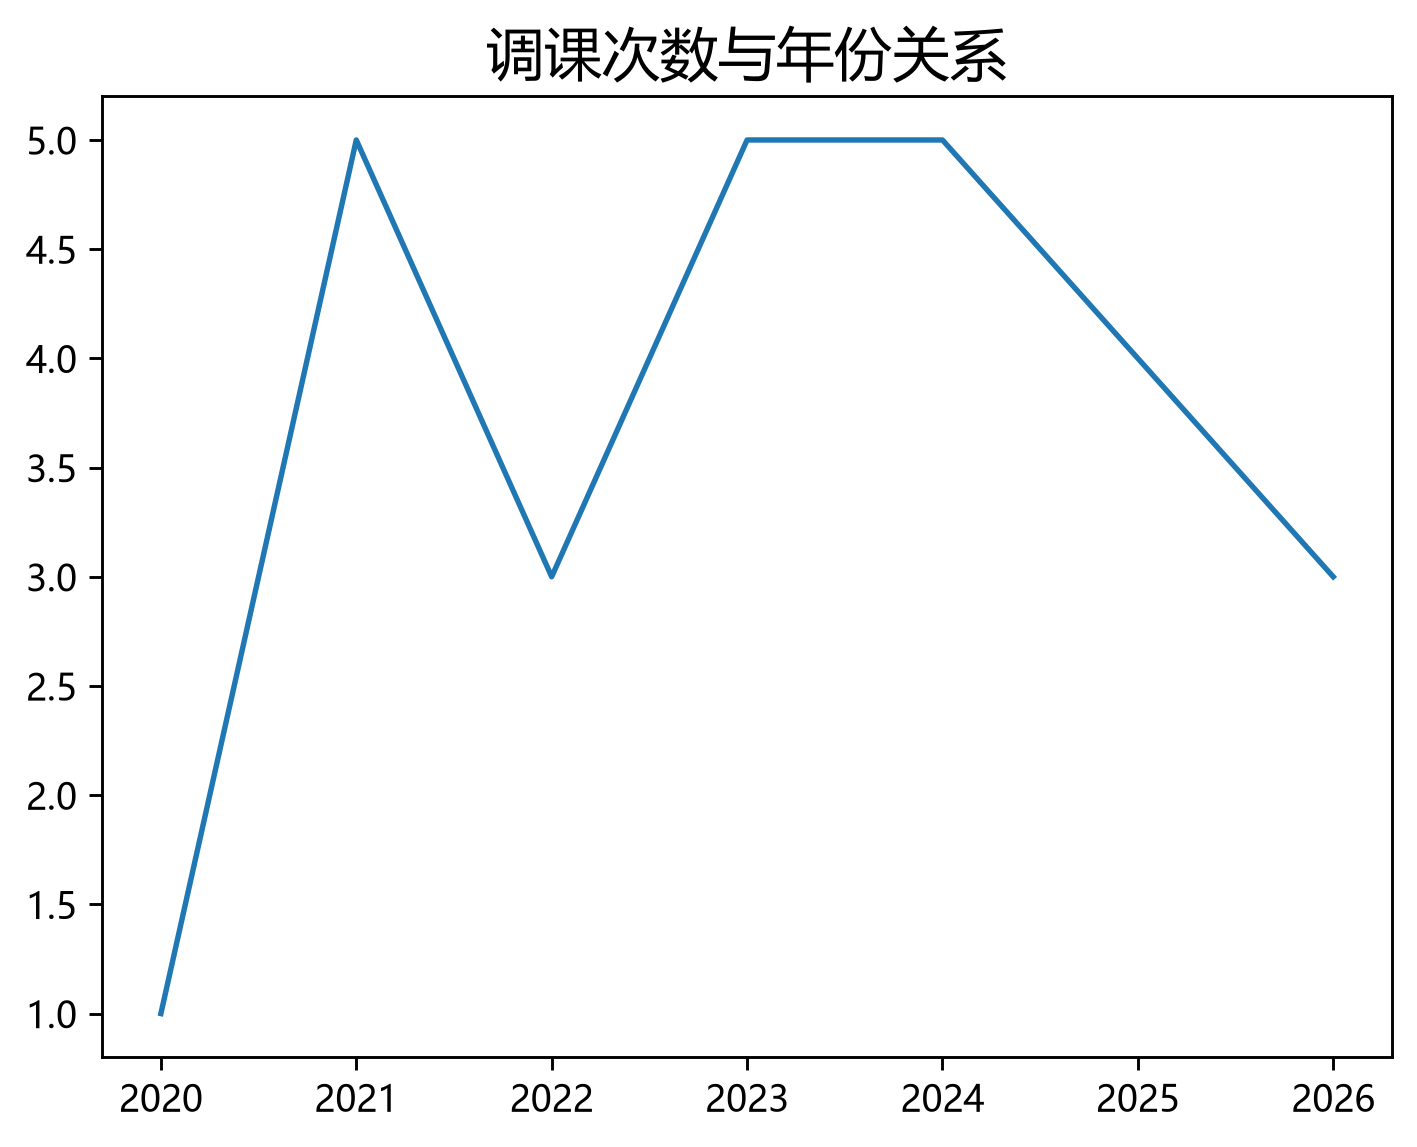

In [27]:
#对调整课程分析(调课时间)
dic = {}
with open('data_file/course_adjust.csv','r',encoding='utf-8') as f:
    for lines in f:
        if '发布时间' in lines:
            print('ok')
            time = lines.replace('发布时间：','')
            time = re.search(r'(\d{4})-\d{2}-\d{2}',time).group(1)
            print(time)
            if time in dic.keys():
                dic[time] += 1
            else:
                dic[time] = 0
    print('调课分析完成')
# 让dic倒过来
dic = dict(reversed(list(dic.items())))

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.figure(dpi=260)
plt.title('调课次数与年份关系',fontsize=16)
fig_1 = plt.plot(dic.keys(),dic.values())
plt.show()


- matplotlib 发布让和下载量的关系

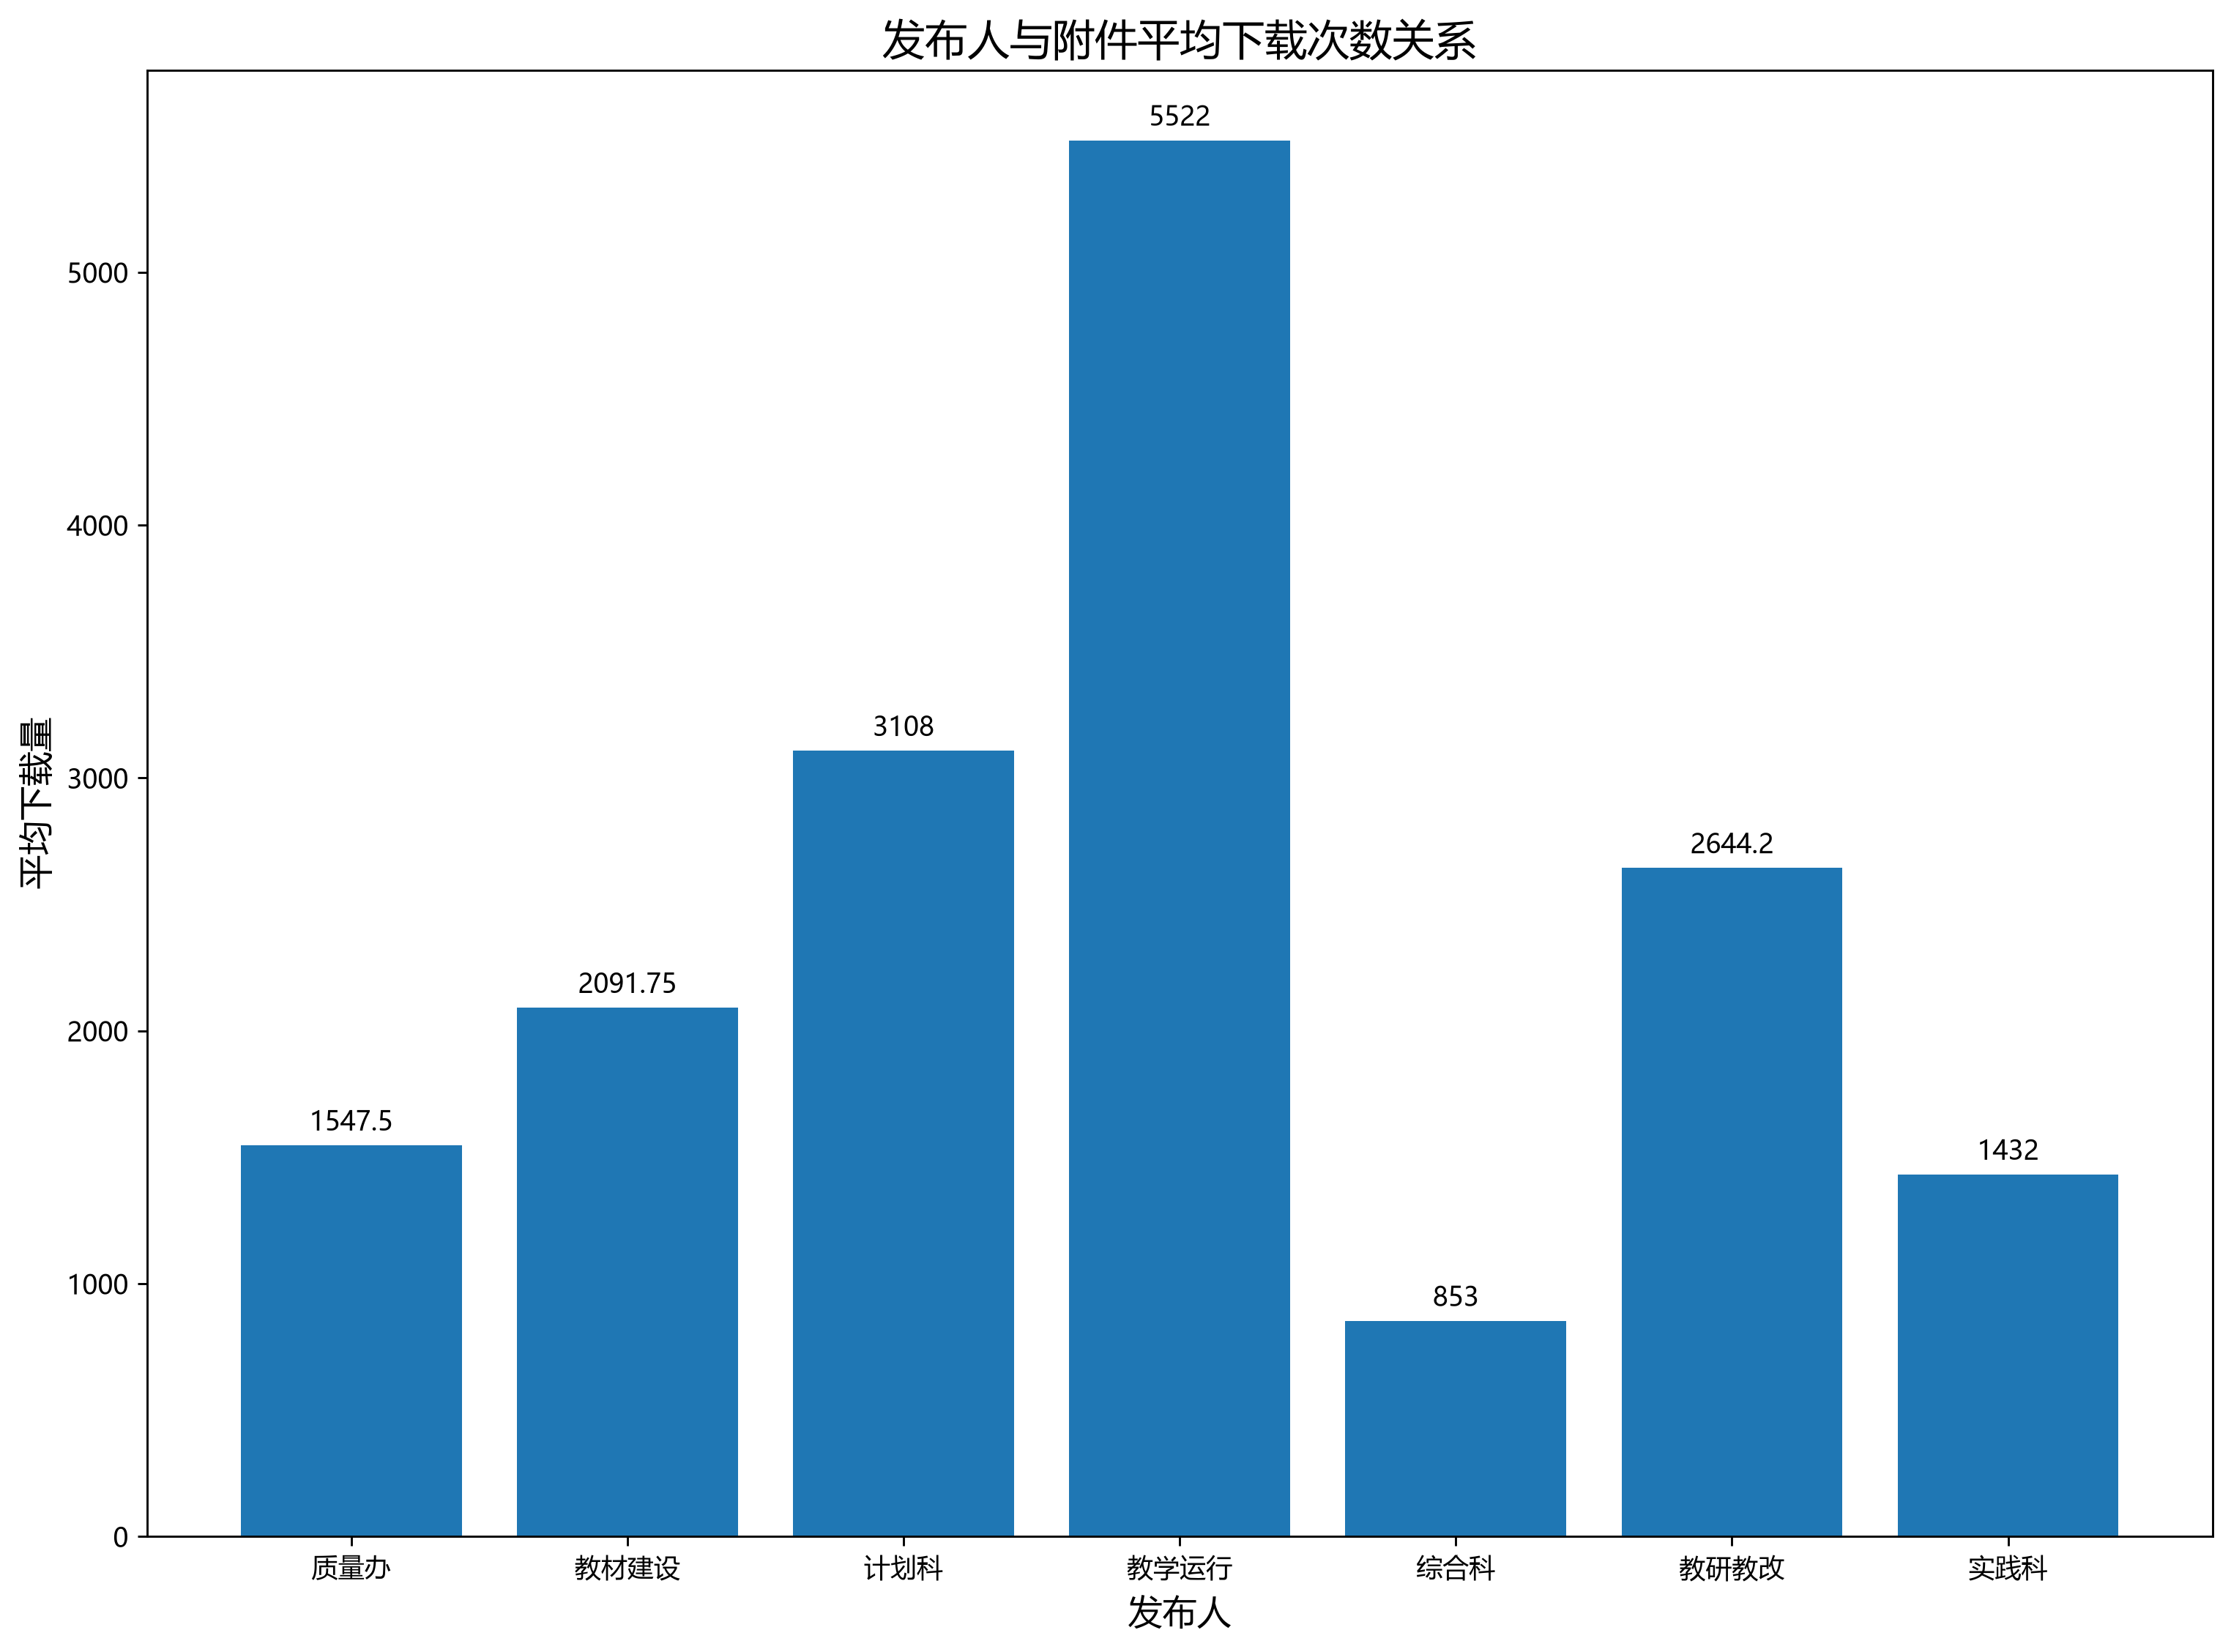

In [43]:
df = pd.read_csv(r'data_file\notice_download.csv',encoding='utf-8')
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.figure(figsize=(14,10),dpi=260)
plt.title('发布人与附件平均下载次数关系',fontsize = 16)
plt.xlabel('发布人',fontsize = 13)
plt.ylabel('平均下载量',fontsize = 13)
fig_2 = plt.bar(df['通知人'],df['平均下载数'])
plt.bar_label(fig_2, padding=3)
plt.show()



In [ ]:
print(notice_people)

质量办     294
教学运行    804
教材建设     82
电教中心     14
计划科     266
综合科     160
教研教改    208
实践科     522
dtype: int64


: 